# Wavebit Tutorial 5
## Non-orthogonal lattices — hexagonal and other tilted cells

Every earlier tutorial used a **rectangular** unit cell: a box of width `period[0]` and height
`period[1]`, repeated across the plane. Many real structures are not on a rectangular grid.
The most common is the **hexagonal** array, which is the standard choice for metalenses — it
packs meta-atoms more densely at the same nearest-neighbour spacing, and its six-fold symmetry
suppresses polarisation anisotropy.

This tutorial covers:

1. why a hexagonal array used to need a workaround, and what that cost
2. the `lattice` keyword, and the **one convention you have to get right**
3. a worked example — the phase library for a visible metalens
4. how the result was checked against a published paper
5. what is not supported yet, and what to use instead

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import wavebit

---

## 1. The problem: a hexagonal array is not a rectangle

RCWA solves **one unit cell** and assumes it repeats forever. So the first question is always:
what is the repeating unit?

For a hexagonal array the natural repeating unit is a **rhombus** (a 60-degree parallelogram)
holding one pillar. Wavebit used to accept only rectangles, so you had to find a rectangle that
also tiles the plane — and the smallest one is `a` by `a*sqrt(3)`, holding **two** pillars.

Let us draw both.

### Spelling the cell

This notebook writes `a1` and `a2` out, which is always available and is what `lattice=`
takes. Three constructors spell the usual ones:

```python
wavebit.rectangular(700., 1100.)              # diag(700, 1100)
wavebit.hexagonal(400.)                       # 120-degree rhombus, the crystallographic setting
wavebit.hexagonal(400., np.radians(60))       # the 60-degree alternative basis, used below
wavebit.oblique(400., 520., np.radians(105))  # angle between a1 and a2, in radians
```

Both hexagonal spellings generate the **same lattice** (`a2_120 = a2_60 - a1`) but are not
the same calculation at finite truncation: `truncation_order` cuts a parallelogram in
`(m, n)`, and a different basis maps that onto a different set of `G`. On the pillar array
here the two agree to 1e-13, because a pillar at the lattice point carries the lattice's own
six-fold symmetry; break that symmetry and they differ by their truncation error.

`A.grid(pixels)` returns the Cartesian coordinates of the raster's pixel centres, so a layer
can be written in coordinates instead of `u*a1 + v*a2` by hand. It is `wavebit.grid(pixels,
lattice=A)` with the basis named once — which is the point, because the cell is needed
**twice** in a raster workflow, here and at `lattice=` on the solver, and the only way that
goes wrong is the two disagreeing.

rhombic cell area   :   138564 nm^2   (1 pillar)
rectangle cell area :   277128 nm^2   (2 pillars)
ratio               :      2.0x


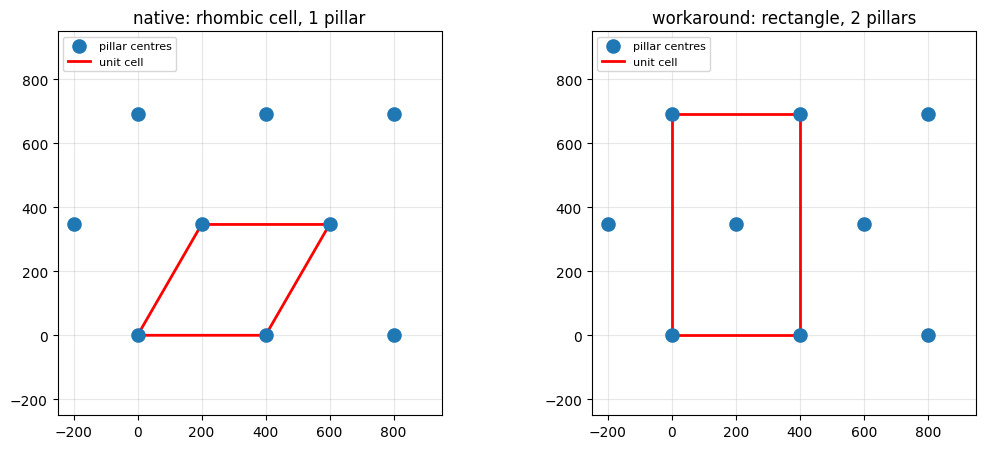

In [2]:
a = 400.0                                   # hex pitch, nm
a1 = np.array([a, 0.0])                     # the two lattice vectors of a hex array
a2 = np.array([a / 2, a * np.sqrt(3) / 2])

# every lattice site within view
sites = np.array([i * a1 + j * a2 for i in range(-2, 4) for j in range(-2, 4)])

fig, ax = plt.subplots(1, 2, figsize=(11, 4.6))
for k, (title, cell) in enumerate([
        ('native: rhombic cell, 1 pillar', np.array([[0, 0], a1, a1 + a2, a2, [0, 0]])),
        ('workaround: rectangle, 2 pillars',
         np.array([[0, 0], [a, 0], [a, a * np.sqrt(3)], [0, a * np.sqrt(3)], [0, 0]]))]):
    ax[k].scatter(sites[:, 0], sites[:, 1], s=90, zorder=3, label='pillar centres')
    ax[k].plot(cell[:, 0], cell[:, 1], 'r-', lw=2, label='unit cell')
    ax[k].set_title(title)
    ax[k].set_aspect('equal')
    ax[k].set_xlim(-250, 950); ax[k].set_ylim(-250, 950)
    ax[k].grid(alpha=.3); ax[k].legend(loc='upper left', fontsize=8)

area_native = abs(a1[0] * a2[1] - a1[1] * a2[0])     # |det| of the two lattice vectors
print(f'rhombic cell area   : {area_native:8.0f} nm^2   (1 pillar)')
print(f'rectangle cell area : {a * a * np.sqrt(3):8.0f} nm^2   (2 pillars)')
print(f'ratio               : {a * a * np.sqrt(3) / area_native:8.1f}x')
plt.tight_layout(); plt.show()

The rectangle is **exactly twice the area**, and that is what it costs.

The number of Fourier orders RCWA has to keep is proportional to the cell area — you need the
same resolution in k-space either way, and a bigger cell means a finer k-space grid. So the
rectangle needs twice the orders. The solve is roughly `O(N^2.7)` in the order count `N`, which
makes the workaround about **4 to 6 times slower** for the same physics.

---

## 2. The `lattice` keyword

Pass the two lattice vectors as the **columns** of a 2x2 matrix:

```python
lattice = np.column_stack((a1, a2))
```

A hand-written 2x2 is a plain array and has no `.grid`; pass the one variable to both places.
The three constructors return a cell object instead, which does have it — `A.grid(pixels)` and
`lattice=A` then spell the basis once, and that is what this notebook uses below.

`period=(Lx, Ly)` still works and still means the rectangular cell `diag(Lx, Ly)` — it is the
default and nothing about it changed. Setting `lattice` selects the non-orthogonal path.

### The one thing you must get right

**Your raster is read in lattice coordinates.** `structure[layer][j, i]` sits at the parametric
point $u = (i + 0.5)/N_x$, $v = (j + 0.5)/N_y$, and **the cell is centred on the origin**:

$$ \mathbf{r} = \left(u - \tfrac{1}{2}\right)\mathbf{a_1} \;+\; \left(v - \tfrac{1}{2}\right)\mathbf{a_2} $$

Axis 1 runs along `a1`, axis 0 along `a2`. If you build the raster on a **Cartesian** grid — the
natural thing to do — and then hand it a tilted `lattice`, you have described a *different
structure*, and **nothing will tell you**. There is no error, and energy is still conserved
perfectly, because conservation does not depend on the geometry being read correctly.

So here is the pattern to copy.

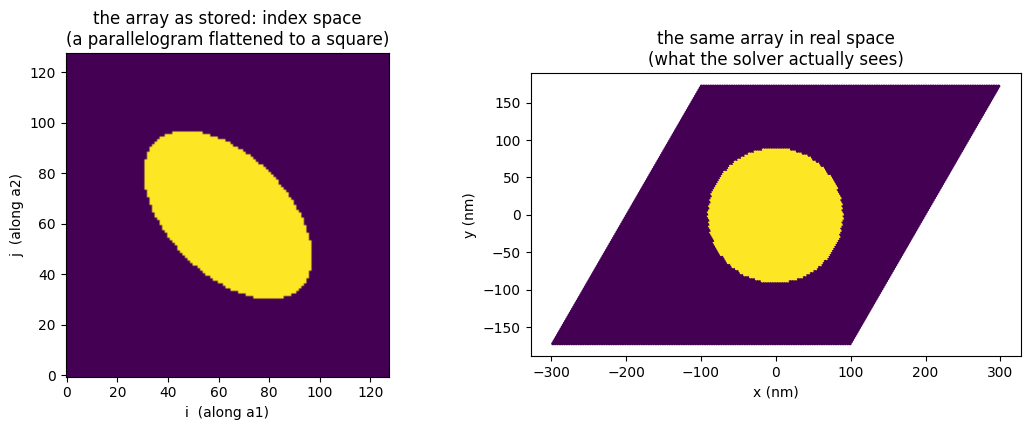

In [3]:
# The cell, named ONCE: `LAT.grid(...)` here and `lattice=LAT` at the solver. This is the same
# a1, a2 written out above -- `hexagonal` is a spelling of that pair, not a different cell.
LAT = wavebit.hexagonal(a, np.radians(60))


def hex_raster(A, n, radius, eps_rod, eps_base=1.0):
    '''A circular pillar on the parametric grid of the cell spanned by A.u, A.v.'''
    # `A.grid` puts the samples at u*a1 + v*a2 AND centres the cell on the origin,
    # so the pillar is centred by writing nothing.
    X, Y = (np.asarray(c) for c in A.grid((n, n)))

    inside = np.zeros(X.shape, dtype=bool)
    for i in (-1, 0, 1):                                # minimum image over the LATTICE,
        for j in (-1, 0, 1):                            # not over a rectangle
            s = i * np.asarray(A.u) + j * np.asarray(A.v)
            inside |= ((X - s[0]) ** 2 + (Y - s[1]) ** 2) <= radius ** 2

    cell = np.full((1, n, n), eps_base)
    cell[0][inside] = eps_rod
    return cell, np.stack([X, Y], axis=-1)


# A raster holds relative permittivity, one number per pixel. The rod is n = 3.48, so
# eps_from_index turns the datasheet number into the quantity the solver takes.
cell, pts = hex_raster(LAT, 128, 90.0, wavebit.eps_from_index(3.48))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
ax[0].imshow(cell[0], origin='lower', cmap='viridis')
ax[0].set_title('the array as stored: index space\n(a parallelogram flattened to a square)')
ax[0].set_xlabel('i  (along a1)'); ax[0].set_ylabel('j  (along a2)')

ax[1].scatter(pts[..., 0], pts[..., 1], c=cell[0], s=2, cmap='viridis')
ax[1].set_title('the same array in real space\n(what the solver actually sees)')
ax[1].set_xlabel('x (nm)'); ax[1].set_ylabel('y (nm)'); ax[1].set_aspect('equal')
plt.tight_layout(); plt.show()

The left panel is what is stored; the right is what it means. The pillar looks circular in real
space and *sheared* in index space — that is correct, and it is the whole point. If your left
panel shows a circle, you have almost certainly built it on a Cartesian grid by mistake.

**Analytic shapes are exempt.** Their `lx`, `ly` are absolute Cartesian lengths and `cx`, `cy`
are a Cartesian displacement from the **centre of the cell**, so a circle stays a circle and a
rectangle stays a rectangle whatever the cell does, and a centred pillar is `cx = cy = 0` on
every cell. Only rasters need the parametric grid.

---

## 3. A worked example: a visible metalens phase library

Here is what a metasurface designer actually asks RCWA for. A lens needs a phase profile, so you
need a **library**: a table of pillar diameter to transmitted phase. It is usable only if the
phase covers a full 2*pi while transmission stays high.

TiO2 pillars on fused silica at 532 nm, hexagonal pitch 350 nm — the visible-metalens geometry
family. We use **analytic shapes** here rather than a raster, so there is no staircase error.

In [4]:
WL, PITCH, HEIGHT = 532.0, 350.0, 600.0
N_TIO2, N_SIO2 = 2.43, 1.46            # refractive indices, as the datasheets give them
EPS_TIO2 = wavebit.eps_from_index(N_TIO2)   # what the solver takes: relative permittivity
EPS_SIO2 = wavebit.eps_from_index(N_SIO2)

b1 = np.array([PITCH, 0.0])
b2 = np.array([PITCH / 2, PITCH * np.sqrt(3) / 2])
LAT = np.column_stack((b1, b2))

# design check: with this pitch, does anything but the zero order reach the substrate?
B = 2 * np.pi * np.linalg.inv(LAT).T
g_min = min(np.linalg.norm(B[:, 0]), np.linalg.norm(B[:, 1]),
            np.linalg.norm(B[:, 0] + B[:, 1]), np.linalg.norm(B[:, 0] - B[:, 1]))
print(f'|G|min = {g_min:.5f} /nm   vs   k0*n_sub = {2*np.pi/WL*N_SIO2:.5f} /nm')
print(f'zero order only: {g_min > 2*np.pi/WL*N_SIO2}')

|G|min = 0.02073 /nm   vs   k0*n_sub = 0.01724 /nm
zero order only: True


In [5]:
diameters = np.arange(80.0, 261.0, 10.0)
rows = []
for d in diameters:
    structure = [{'background': 1.0, 'shapes': [
        {'type': 'circle', 'cx': 0.0, 'cy': 0.0,
         'lx': float(d), 'material': EPS_TIO2}]}]
    s = wavebit.rcwa(backend=0, structure=structure, truncation_order=dict(x=8, y=8), thickness=[HEIGHT],
                       wavelength=WL, top=1.0, bot=EPS_SIO2,
                       theta=0.0, phi=0.0, psi=0.0,
                       factorization='nvf', lattice=LAT)
    # psi=0 is pure p, so the s channel is identically zero there. Read the pure-s
    # variant, where t_s carries the whole amplitude. A round pillar at normal incidence
    # is polarisation-blind. Lowercase t_s is the complex Fresnel amplitude -- uppercase
    # T_s is its efficiency, which has no phase to unwrap.
    sub = s.solve().s_inc
    ts = np.asarray(sub.t_s)
    c = (ts.shape[0] // 2, ts.shape[1] // 2)
    rows.append((d, complex(ts[c]), float(np.sum(np.asarray(sub.T)))))

diam = np.array([r[0] for r in rows])
phase = np.unwrap(np.angle([r[1] for r in rows]))
phase -= phase[0]
trans = np.array([r[2] for r in rows])
print(f'phase span : {phase[-1]:.3f} rad  =  {phase[-1] / (2*np.pi):.2f} x 2pi')

phase span : 6.649 rad  =  1.06 x 2pi


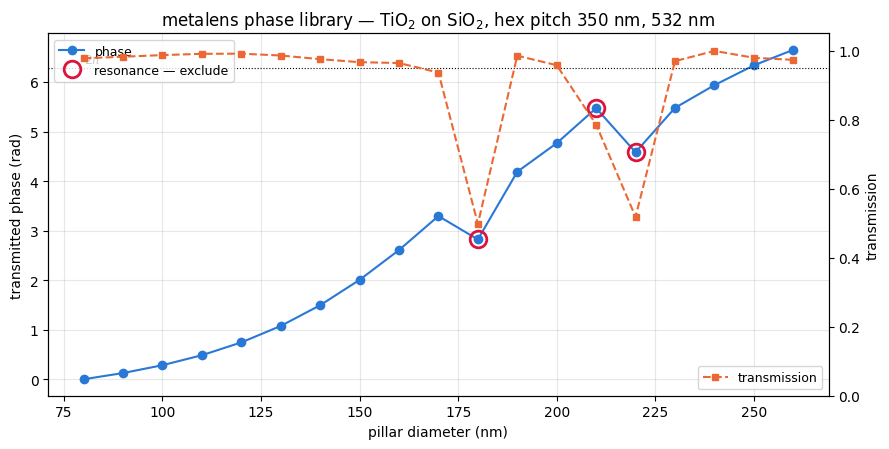

usable diameters      : 16 of 19
excluded (resonances) : [180, 210, 220] nm
phase span            : 6.649 rad (1.06 x 2pi)
worst transmission    : 0.9364
monotonic (usable)    : True


In [6]:
good = trans > 0.9
fig, ax1 = plt.subplots(figsize=(9, 4.6))
ax1.plot(diam, phase, 'o-', color='#2a78d6', label='phase')
ax1.plot(diam[~good], phase[~good], 'o', ms=12, mfc='none', mec='crimson', mew=2,
         label='resonance — exclude')
ax1.axhline(2 * np.pi, ls=':', c='k', lw=.8)
ax1.text(diam[0], 2 * np.pi + .1, '2$\\pi$', fontsize=9)
ax1.set_xlabel('pillar diameter (nm)'); ax1.set_ylabel('transmitted phase (rad)')
ax1.legend(loc='upper left', fontsize=9)

ax2 = ax1.twinx()
ax2.plot(diam, trans, 's--', color='#eb6834', ms=4, label='transmission')
ax2.set_ylabel('transmission'); ax2.set_ylim(0, 1.05)
ax2.legend(loc='lower right', fontsize=9)
ax1.set_title('metalens phase library — TiO$_2$ on SiO$_2$, hex pitch 350 nm, 532 nm')
ax1.grid(alpha=.3)
plt.tight_layout(); plt.savefig('oblique_metalens_library.png', dpi=140); plt.show()

print(f'usable diameters      : {good.sum()} of {len(diam)}')
print(f'excluded (resonances) : {[int(d) for d in diam[~good]]} nm')
print(f'phase span            : {phase[-1]:.3f} rad ({phase[-1]/(2*np.pi):.2f} x 2pi)')
print(f'worst transmission    : {trans[good].min():.4f}')
print(f'monotonic (usable)    : {bool(np.all(np.diff(phase[good]) > 0))}')

That is a usable library: once the three resonant diameters are excluded it covers **a full
2*pi of phase**, rises **monotonically** (so phase-to-diameter inverts uniquely, which is what
a design step needs), and holds transmission above 0.93.

Note `|t|**2` is not the transmitted efficiency — power into a substrate of index `n_sub` carries
a factor of `n_sub`. If `abs(t)**2` and `sum(T)` disagree by about that factor, nothing is
wrong; if they disagree any other way, something is.

---

## 4. Is it right? A published benchmark

The strongest check available is a case with numbers in the literature: the **checkerboard**
crossed grating from Li, *JOSA A* **14**(10), 2758 (1997), tabulated by Demésy et al. in
*Gratings: Theory and Numeric Applications* (2012), Table 5.4.

It is a well-chosen case here, because a checkerboard **is** an oblique-cell problem: two blocks
on a square cell, or **one block on a square rotated 45 degrees**. That rotated cell is not
axis-aligned, so this exercises exactly the code path this tutorial is about.

In [7]:
side = 1.25                                        # square side; cell edge is side*sqrt(2)
c1, c2 = np.array([side, side]), np.array([side, -side])
basis = np.column_stack((c1, c2))

from wavebit._core.lattice import is_axis_aligned
print(f'cell edge |a1| = {np.linalg.norm(c1):.6f}   paper says 5*sqrt(2)/4 = {5*np.sqrt(2)/4:.6f}')
print(f'axis aligned?  {is_axis_aligned(basis)}   <- False means the oblique path carries it')

structure = [{'background': 1.0, 'shapes': [
    {'type': 'rectangle', 'cx': 0.0, 'cy': 0.0,
     'lx': side, 'ly': side, 'material': 2.25}]}]      # the paper's n = 1.5 square, as eps
# psi0 = 45 deg in the paper is measured from ITS cell axes, which are this rotated basis,
# so in Wavebit's Cartesian frame it is psi = pi/2.
s = wavebit.rcwa(backend=0, structure=structure, truncation_order=dict(x=16, y=16), thickness=[1.0], wavelength=1.0,
                   top=2.25, bot=1.0, theta=0.0, phi=0.0, psi=np.pi / 2,
                   factorization='nvf', lattice=basis)
res = s.solve().given
ti = np.asarray(res.T); cc = (ti.shape[0] // 2, ti.shape[1] // 2)

FMM = {(-1,-1):0.04308, (-1,0):0.12860, (-1,1):0.06196, (0,-1):0.12860, (0,0):0.17486,
       (0,1):0.12860, (1,-1):0.06196, (1,0):0.12860, (1,1):0.04308}
FEM = {(-1,-1):0.04333, (-1,0):0.12845, (-1,1):0.06176, (0,-1):0.12838, (0,0):0.17577,
       (0,1):0.12839, (1,-1):0.06177, (1,0):0.12843, (1,1):0.04332}
keys = sorted(FEM)
mine = [float(ti[cc[0] + n, cc[1] + m]) for n, m in keys]

print(f'\n{"order":>8} {"Li FMM":>9} {"FEM":>9} {"Wavebit":>10} {"vs FEM":>9}')
for k, v in zip(keys, mine):
    print(f'{str(k):>8} {FMM[k]:>9.5f} {FEM[k]:>9.5f} {v:>10.5f} {v - FEM[k]:>9.5f}')
print(f'\nworst over all nine : {max(abs(v - FEM[k]) for k, v in zip(keys, mine)):.2e}')
print(f'reflected sum       : {float(np.asarray(res.R).sum()):.5f}   (paper 0.10040)')

cell edge |a1| = 1.767767   paper says 5*sqrt(2)/4 = 1.767767
axis aligned?  False   <- False means the oblique path carries it



   order    Li FMM       FEM    Wavebit    vs FEM
(-1, -1)   0.04308   0.04333    0.04316  -0.00017
 (-1, 0)   0.12860   0.12845    0.12850   0.00005
 (-1, 1)   0.06196   0.06176    0.06178   0.00002
 (0, -1)   0.12860   0.12838    0.12850   0.00012
  (0, 0)   0.17486   0.17577    0.17554  -0.00023
  (0, 1)   0.12860   0.12839    0.12850   0.00011
 (1, -1)   0.06196   0.06177    0.06178   0.00001
  (1, 0)   0.12860   0.12843    0.12850   0.00007
  (1, 1)   0.04308   0.04332    0.04316  -0.00016

worst over all nine : 2.30e-04
reflected sum       : 0.10057   (paper 0.10040)


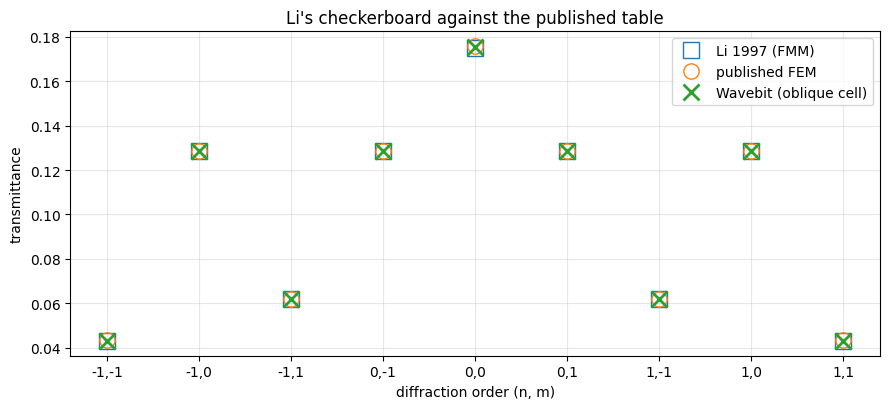

In [8]:
x = np.arange(len(keys))
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(x, [FMM[k] for k in keys], 's', ms=11, mfc='none', label='Li 1997 (FMM)')
ax.plot(x, [FEM[k] for k in keys], 'o', ms=11, mfc='none', label='published FEM')
ax.plot(x, mine, 'x', ms=11, mew=2, label='Wavebit (oblique cell)')
ax.set_xticks(x); ax.set_xticklabels([f'{n},{m}' for n, m in keys])
ax.set_xlabel('diffraction order (n, m)'); ax.set_ylabel('transmittance')
ax.set_title("Li's checkerboard against the published table")
ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig('oblique_li_benchmark.png', dpi=140); plt.show()

All nine orders agree to **2e-4**. For scale, the paper's own two methods differ from each other
by 9e-4 on the zeroth order — so this sits closer to the FEM reference than the two published
methods sit to each other.

**One trap worth copying from the code above.** The paper's `psi0 = 45 deg` is measured from *its*
cell axes, which are the rotated basis, so here it becomes `psi = pi/2`. Get the frame wrong and
the zeroth order barely moves — it is polarisation-blind on a four-fold symmetric cell — while
the other eight rearrange, and the error grows to 2e-2. **Never validate on the zeroth order
alone.**

---

## 5. What is not supported yet

One combination refuses to run on a tilted cell rather than answering. It *would* produce a
plausible, wrong number, with energy conserved — which is exactly why it raises.

| | on a tilted cell | use instead |
|---|---|---|
| `factorization='li'` | refused | `factorization='nvf'` — it **contains** Li's rules as the constant-normal case, and measures equal or better everywhere tested |

The block modeller (`structure=[[background, [[shape...]]]]`) was refused here too, on the same
grounds — it rasterised onto a rectangular grid of its own. That whole path was removed on
2026-08-26 and the spelling is refused on every cell now, tilted or not.

Everything else works: rasters (sampled or integrated coefficients), analytic shapes summed or
painted, and field reconstruction.

**Field reconstruction has one wrinkle.** Samples land on the cell's parallelogram, so the
returned grid is indexed by `(v, u)` and not `(y, x)`. Convert before plotting:

```python
u = np.linspace(0, 1, sample_x); v = np.linspace(0, 1, sample_y)
U, V = np.meshgrid(u, v)
X, Y = U * a1[0] + V * a2[0], U * a1[1] + V * a2[1]
plt.pcolormesh(X, Y, np.abs(field[0, z, :, :, 0]))     # pcolormesh, not imshow
```

---

## Where to go next

* [`docs/oblique-lattice.md`](../docs/oblique-lattice.md) — the reference: every measurement,
  every refusal and its reason, and how the feature was validated.
* the oblique-lattice study under `studies/` reproduces all of it, one subcommand per check.
* [Tutorial 4](04-nvf-fourier-factorization.ipynb) — why `factorization='nvf'` is the default
  choice here, which matters more than the lattice for a curved boundary.